# **Tecnicas de Aprendizaje Automatico**

# Carga de Dataset

En esta primera fase importamos las librerías y la carga de los distintos datasets que se van a utilizar en el análisis.

In [85]:
import pandas as pd # para la manipulación y análisis de datos

# Cargar datasets
volumen = pd.read_csv("20250804_datosvolumen.csv", sep=";", encoding="latin-1")
velocidad = pd.read_csv("20250804_datosvelocidad.csv", sep=";", encoding="latin-1")
estaciones = pd.read_csv("estaciones.csv", sep=";", encoding="latin-1")

Se cargan tres datasets:

- **volumen:** contiene el número de vehículos por carril, diferenciando entre ligeros y pesados.

- **velocidad:** recoge información de velocidades, distribuciones por intervalos y velocidad media.

- **estaciones:** incluye información geográfica y descriptiva de las estaciones de medida.

Utilizamos sep=";" porque los archivos están separados por punto y coma y encoding="latin-1" para evitar problemas con caracteres especiales.

### **Vista preliminar de los datos**

#### <u>Volumen</u>

In [86]:
volumen.head()

,Estacion,Fecha,Hora,Carril 1 ligeros,Carril 1 pesados,Carril 2 ligeros,Carril 2 pesados,Carril 3 ligeros,Carril 3 pesados,Carril 4 ligeros,Carril 4 pesados,Carril 5 ligeros,Carril 5 pesados,Carril 6 ligeros,Carril 6 pesados
0,1,04/08/2025,01:00,50,4,0,0,0,0,27,3,19,0,0,0
1,1,04/08/2025,02:00,27,1,0,0,0,0,17,0,7,0,0,0
2,1,04/08/2025,03:00,17,3,0,0,0,0,10,0,4,1,0,0
3,1,04/08/2025,04:00,17,6,0,0,0,0,11,2,7,2,0,0
4,1,04/08/2025,05:00,26,1,0,0,0,0,21,3,15,0,0,0


**Deteccion de errores en el dataset:**

- Espacios al principio y al final de cada dato del dataset

- Horas inexistentes como 24:00

#### <u>Velocidad</u>

In [87]:
velocidad.head()

,Fecha,Hora,Sistema,ETD,Detector,0-50 (km/h),50-80 (km/h),80-120 (km/h),120-255 (km/h),Velocidad media (km/h),0-6 (m),6-999 (m),Vehículos totales,Unnamed: 13
0,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Rápido ERRENTERIA AP-8,0,0,0,0,"0,0",0,0,0,NaN
1,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...","Lento USURBIL, AP-8",11,16,0,0,"48,7",22,5,27,NaN
2,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...","Central USURBIL, AP-8",0,27,28,0,"82,82",52,3,55,NaN
3,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Lento ERRENTERIA AP-8,0,10,1,0,"68,18",10,1,11,NaN
4,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Central ERRENTERIA AP-8,0,15,21,0,"85,42",33,3,36,NaN


**Deteccion de errores en el dataset:**

- Columna vacia

- Horas inexistentes como 24:00 o 24:30

#### <u>Estaciones</u>

In [88]:
estaciones.head()

,System,ETD code,System code,Description,Country code,Country,Municipality code,Municipality,Territory code,Territory,Postal code,GPSX,GPSY,X,Y
GI-2132,1,1,"[GI-2132] 1-ETD LASARTE-ORIA-ASTIGARRAGA, GI-...",108,España,,,20,Gipuzkoa,,580428.65,4792191.27,-2.008765,43.278246,
GI-636,3,1,"[GI-636] 3-ETD PASAIA-IRUN, GI-636 pk 7,900, ...",108,España,53,LEZO,20,Gipuzkoa,20100,594584.89,4798000.13,-1.833330,43.328896,
N-634,11,1,"[N-634] 11-ETD SAN SEBASTIÁN-SANTANDER, N-634...",108,España,30,EIBAR,20,Gipuzkoa,20600,545592.28,4782339.10,-2.438889,43.192449,
N-I,12,1,"[N-I] 12-ETD VITORIA-GASTEIZ-LASARTE-ORIA, N-...",108,España,71,TOLOSA,20,Gipuzkoa,20400,575944.00,4778800.00,-2.065870,43.158142,
GI-20,16,1,"[GI-20] 16-ETD USURBIL, AP-8-ERRENTERIA,AP-8,...",108,España,69,DONOSTIA-SAN SEBASTIAN,20,Gipuzkoa,0,583607.00,4795202.00,-1.969142,43.305006,


**Deteccion de errores en el dataset:**

- Nombres de las columnas desplazados a la derecha

- Datos vacios en las columnas

- Espacios al principio y al final de cada dato del dataset

# Correcciones

## Correcciones en la estructura de las tablas

### **Correcciones en el dataset de estaciones**

Aqui se limpia y corrige el dataset de estaciones para asegurar que los datos sean utilizables en codigos posteriores.

#### <u>Correccion de desplazamiento de columnas</u>

Para solucionarlo, se limita la lectura a las primeras 15 columnas, que son las esperadas.

In [89]:
estaciones = pd.read_csv(
    "estaciones.csv",
    sep=";",
    encoding="latin-1",
    usecols=range(15) # leer solo las columnas válidas
)

estaciones.head()

,System,ETD code,System code,Description,Country code,Country,Municipality code,Municipality,Territory code,Territory,Postal code,GPSX,GPSY,X,Y
0,GI-2132,1,1,"[GI-2132] 1-ETD LASARTE-ORIA-ASTIGARRAGA, GI-...",108,España,,,20,Gipuzkoa,,580428.65,4792191.27,-2.008765,43.278246
1,GI-636,3,1,"[GI-636] 3-ETD PASAIA-IRUN, GI-636 pk 7,900, ...",108,España,53,LEZO,20,Gipuzkoa,20100,594584.89,4798000.13,-1.833330,43.328896
2,N-634,11,1,"[N-634] 11-ETD SAN SEBASTIÁN-SANTANDER, N-634...",108,España,30,EIBAR,20,Gipuzkoa,20600,545592.28,4782339.10,-2.438889,43.192449
3,N-I,12,1,"[N-I] 12-ETD VITORIA-GASTEIZ-LASARTE-ORIA, N-...",108,España,71,TOLOSA,20,Gipuzkoa,20400,575944.00,4778800.00,-2.065870,43.158142
4,GI-20,16,1,"[GI-20] 16-ETD USURBIL, AP-8-ERRENTERIA,AP-8,...",108,España,69,DONOSTIA-SAN SEBASTIAN,20,Gipuzkoa,0,583607.00,4795202.00,-1.969142,43.305006


#### <u>Correccion de nombres de columnas</u>

Se eliminan espacios innecesarios en los nombres de columnas para evitar errores al acceder a ellas posteriormente.

In [90]:
# Eliminamos espacios en blanco al principio y al final de los nombres de columnas
estaciones.columns = estaciones.columns.str.strip()

#### <u>Correccion de espacios en las variables de las columnas</u>

Se eliminan espacios innecesarios en los datos de las columnas para evitar errores al acceder a ellos posteriormente.

In [91]:
# Recorremos todas las columnas de tipo texto
for col in estaciones.select_dtypes(include=["object", "string"]).columns:
    # Eliminamos espacios en blanco al inicio y final de cada valor
    estaciones[col] = estaciones[col].str.strip()

#### <u>Correccion de filas con datos en blanco</u>

Identificamos que columnas estan con valores vacíos que podrían causar problemas en análisis o joins.

In [92]:
for col in estaciones.columns:
    if estaciones[col].dtype in ["object", "string"]:
        vacios = (estaciones[col] == "").sum()
        if vacios > 0:
            print(col, "->", vacios)

Municipality code -> 20
Municipality -> 20
Postal code -> 20


Reemplazo de valores vacíos por "Desconocido"

In [93]:
estaciones["Municipality"] = estaciones["Municipality"].replace("", "Desconocido")
estaciones["Municipality code"] = estaciones["Municipality code"].replace("", "Desconocido")
estaciones["Postal code"] = estaciones["Postal code"].replace("", "Desconocido")


In [94]:
estaciones.head()

,System,ETD code,System code,Description,Country code,Country,Municipality code,Municipality,Territory code,Territory,Postal code,GPSX,GPSY,X,Y
0,GI-2132,1,1,"[GI-2132] 1-ETD LASARTE-ORIA-ASTIGARRAGA, GI-2...",108,España,Desconocido,Desconocido,20,Gipuzkoa,Desconocido,580428.65,4792191.27,-2.008765,43.278246
1,GI-636,3,1,"[GI-636] 3-ETD PASAIA-IRUN, GI-636 pk 7,900, G...",108,España,53,LEZO,20,Gipuzkoa,20100,594584.89,4798000.13,-1.833330,43.328896
2,N-634,11,1,"[N-634] 11-ETD SAN SEBASTIÁN-SANTANDER, N-634 ...",108,España,30,EIBAR,20,Gipuzkoa,20600,545592.28,4782339.10,-2.438889,43.192449
3,N-I,12,1,"[N-I] 12-ETD VITORIA-GASTEIZ-LASARTE-ORIA, N-I...",108,España,71,TOLOSA,20,Gipuzkoa,20400,575944.00,4778800.00,-2.065870,43.158142
4,GI-20,16,1,"[GI-20] 16-ETD USURBIL, AP-8-ERRENTERIA,AP-8, ...",108,España,69,DONOSTIA-SAN SEBASTIAN,20,Gipuzkoa,0,583607.00,4795202.00,-1.969142,43.305006


Se realiza una segunda comprobación para asegurar que no quedan valores vacíos

In [95]:
for col in estaciones.columns:
    if estaciones[col].dtype in ["object", "string"]:
        vacios = (estaciones[col] == "").sum()
        if vacios > 0:
            print(col, "->", vacios)

### **Correcciones en el dataset de velocidad**

En esta sección se realizan varias transformaciones para limpiar y preparar el dataset de velocidad.

#### <u>Eliminacion de la columna Unnamed: 13 del csv de velocidad</u>

Se elimina una columna sin utilidad (Unnamed: 13)

In [96]:
velocidad = velocidad.drop(columns=["Unnamed: 13"])

velocidad.head()

,Fecha,Hora,Sistema,ETD,Detector,0-50 (km/h),50-80 (km/h),80-120 (km/h),120-255 (km/h),Velocidad media (km/h),0-6 (m),6-999 (m),Vehículos totales
0,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Rápido ERRENTERIA AP-8,0,0,0,0,"0,0",0,0,0
1,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...","Lento USURBIL, AP-8",11,16,0,0,"48,7",22,5,27
2,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...","Central USURBIL, AP-8",0,27,28,0,"82,82",52,3,55
3,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Lento ERRENTERIA AP-8,0,10,1,0,"68,18",10,1,11
4,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Central ERRENTERIA AP-8,0,15,21,0,"85,42",33,3,36


#### <u>Correccion de nombres de columnas</u>

Se eliminan espacios en blanco en los nombres de columnas.

In [97]:
# Eliminamos espacios en blanco al principio y al final de los nombres de columnas
velocidad.columns = velocidad.columns.str.strip()

#### <u>Correccion de espacios en las variables de las columnas</u>

Se eliminan espacios innecesarios en los datos de las columnas para evitar errores al acceder a ellos posteriormente.

In [98]:
# Recorremos todas las columnas de tipo texto
for col in velocidad.select_dtypes(include=["object", "string"]).columns:
    # Eliminamos espacios en blanco al inicio y final de cada valor
    velocidad[col] = velocidad[col].str.strip()

### **Correcciones en el dataset de volumen**

#### <u>Correccion de nombres de columnas</u>

Eliminamos espacios en blanco al inicio y final de cada valor

In [99]:
# Eliminamos espacios en blanco al principio y al final
volumen.columns = volumen.columns.str.strip()

#### <u>Correccion de espacios en las variables de las columnas</u>

Se eliminan espacios innecesarios en los datos de las columnas para evitar errores al acceder a ellos posteriormente.

In [100]:
# Recorremos todas las columnas de tipo texto
for col in volumen.select_dtypes(include=["object", "string"]).columns:
    # Eliminamos espacios en blanco al inicio y final de cada valor
    volumen[col] = volumen[col].str.strip()

## Correcciones en los datos de las columnas

### **Correccion de las fechas de los datasets**

#### <u>Conversion de fecha del volumen</u>

In [101]:
# Limpia espacios en fecha y hora
volumen["Fecha"] = volumen["Fecha"].str.strip()
volumen["Hora"] = volumen["Hora"].str.strip()

# Detecta registros con hora "24:00"
mask_24 = volumen["Hora"] == "24:00"

# Convertierte a 00:00
volumen.loc[mask_24, "Hora"] = "00:00"

# Sumar 1 día a la fecha en esos casos
volumen.loc[mask_24, "Fecha"] = (
    pd.to_datetime(volumen.loc[mask_24, "Fecha"], dayfirst=True)
    + pd.Timedelta(days=1)
).dt.strftime("%d/%m/%Y")

# Creamos la columna datetime combinando fecha y hora
volumen["datetime"] = pd.to_datetime(
    volumen["Fecha"] + " " + volumen["Hora"],
    dayfirst=True
)

In [102]:
# Comprobación del tipo de dato
print(volumen["datetime"].dtype)

# Imprimimos el dataset de velodicad con la nueva columna y otras columnas
print(volumen[["Fecha", "Hora", "datetime"]].head())

datetime64[us]
        Fecha   Hora            datetime
0  04/08/2025  01:00 2025-08-04 01:00:00
1  04/08/2025  02:00 2025-08-04 02:00:00
2  04/08/2025  03:00 2025-08-04 03:00:00
3  04/08/2025  04:00 2025-08-04 04:00:00
4  04/08/2025  05:00 2025-08-04 05:00:00


#### <u>Conversor de fecha de la velocidad</u>

In [103]:
# Limpiar espacios en columnas de fecha y hora
velocidad["Fecha"] = velocidad["Fecha"].str.strip()
velocidad["Hora"] = velocidad["Hora"].str.strip()

# Nos quedamos con la hora inicial del intervalo (osea, lo de antes del " - ")
velocidad["Hora_inicio"] = velocidad["Hora"].str.split(" - ").str[0]

# Detectar 24:XX
mask_24 = velocidad["Hora_inicio"].str.startswith("24")

# Sustituir 24:XX por 00:XX
velocidad.loc[mask_24, "Hora_inicio"] = velocidad.loc[mask_24, "Hora_inicio"].str.replace("24:", "00:", regex=False)

# Sumar un día a la fecha en esos casos
velocidad.loc[mask_24, "Fecha"] = (
    pd.to_datetime(velocidad.loc[mask_24, "Fecha"])
    + pd.Timedelta(days=1)
).dt.strftime("%Y-%m-%d")

# Crear columna datetime combinando fecha y hora
velocidad["datetime"] = pd.to_datetime(
    velocidad["Fecha"] + " " + velocidad["Hora_inicio"]
)

In [104]:
print(velocidad["datetime"].dtype) # Imprimimos el tipo de la columna

# Imprimimos el dataset de velodicad con la nueva columna y otras columnas
print(velocidad[["Fecha", "Hora", "Hora_inicio", "datetime"]].head())

datetime64[us]
        Fecha                 Hora Hora_inicio            datetime
0  2025-08-04  01:00:00 - 01:30:00    01:00:00 2025-08-04 01:00:00
1  2025-08-04  01:00:00 - 01:30:00    01:00:00 2025-08-04 01:00:00
2  2025-08-04  01:00:00 - 01:30:00    01:00:00 2025-08-04 01:00:00
3  2025-08-04  01:00:00 - 01:30:00    01:00:00 2025-08-04 01:00:00
4  2025-08-04  01:00:00 - 01:30:00    01:00:00 2025-08-04 01:00:00


### **Cambio de tipo de las columnas de velocidad media y vehiculos**

In [105]:
# Convertir velocidad a float (reemplazando coma por punto)
velocidad["Velocidad media (km/h)"] = (
    velocidad["Velocidad media (km/h)"]
    .astype(str)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

# Convertir número de vehículos a entero
velocidad["Vehículos totales"] = velocidad["Vehículos totales"].astype(int)

### **Cambio de media hora en madia hora a de hora en hora**

In [106]:
# Redondear el datetime a la hora
velocidad["datetime_hora"] = velocidad["datetime"].dt.floor("h")

# Vista del dataset de velocidad
velocidad.head()

,Fecha,Hora,Sistema,ETD,Detector,0-50 (km/h),50-80 (km/h),80-120 (km/h),120-255 (km/h),Velocidad media (km/h),0-6 (m),6-999 (m),Vehículos totales,Hora_inicio,datetime,datetime_hora
0,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Rápido ERRENTERIA AP-8,0,0,0,0,0.00,0,0,0,01:00:00,2025-08-04 01:00:00,2025-08-04 01:00:00
1,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...","Lento USURBIL, AP-8",11,16,0,0,48.70,22,5,27,01:00:00,2025-08-04 01:00:00,2025-08-04 01:00:00
2,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...","Central USURBIL, AP-8",0,27,28,0,82.82,52,3,55,01:00:00,2025-08-04 01:00:00,2025-08-04 01:00:00
3,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Lento ERRENTERIA AP-8,0,10,1,0,68.18,10,1,11,01:00:00,2025-08-04 01:00:00,2025-08-04 01:00:00
4,2025-08-04,01:00:00 - 01:30:00,GI-20,"[GI-20] 249-ETD USURBIL, AP-8-ERRENTERIA AP-8,...",Central ERRENTERIA AP-8,0,15,21,0,85.42,33,3,36,01:00:00,2025-08-04 01:00:00,2025-08-04 01:00:00


#### Agrupar con media ponderada

In [107]:
# Crear velocidad ponderada (velocidad * número de vehículos)
velocidad["velocidad_ponderada"] = (
    velocidad["Velocidad media (km/h)"] * velocidad["Vehículos totales"]
)

Lo que acabamos de hacer permite obtener una media horaria teniendo en cuenta el peso de cada intervalo según su volumen de tráfico.

In [108]:
# Agrupa por sistema, ETD y hora, y suma el número de vehículos y la velocidad_ponderada
velocidad_hora = (
    velocidad
    .groupby(["Sistema", "ETD", "datetime_hora"])
    .agg({
        "Vehículos totales": "sum",
        "velocidad_ponderada": "sum"
    })
    .reset_index()
)

In [109]:
# Calculamos la velocidad media ponderada final
velocidad_hora["velocidad_media"] = (
    velocidad_hora["velocidad_ponderada"] /
    velocidad_hora["Vehículos totales"]
)

In [110]:
# Eliminamos la columna auxiliar
velocidad_hora = velocidad_hora.drop(columns=["velocidad_ponderada"])

In [111]:
# Resultado final del dataset de velocidad
velocidad_hora.head()

,Sistema,ETD,datetime_hora,Vehículos totales,velocidad_media
0,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 01:00:00,396,103.055404
1,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 02:00:00,245,104.042041
2,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 03:00:00,203,101.450739
3,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 04:00:00,234,102.264872
4,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 05:00:00,337,102.271276


# Unificación de los datasets

En esta sección se combinan los tres datasets

Antes de unir, miramos que claves coinciden

In [112]:
# Revisamos el identificador de estación en volumen
print("---------- Volumen ----------")
print(volumen["Estacion"].head())

print(f"\n")

# Revisamos el identificador de velocidad
print("---------- Velocidad ----------")
print(velocidad_hora["ETD"].head())

print(f"\n")

# Revisamos el identificador en estaciones
print("---------- Estaciones ----------")
print(estaciones[["ETD code", "Description"]].head())

---------- Volumen ----------
0    1
1    1
2    1
3    1
4    1
Name: Estacion, dtype: int64


---------- Velocidad ----------
0    [A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...
1    [A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...
2    [A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...
3    [A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...
4    [A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...
Name: ETD, dtype: str


---------- Estaciones ----------
   ETD code                                        Description
0         1  [GI-2132] 1-ETD LASARTE-ORIA-ASTIGARRAGA, GI-2...
1         3  [GI-636] 3-ETD PASAIA-IRUN, GI-636 pk 7,900, G...
2        11  [N-634] 11-ETD SAN SEBASTIÁN-SANTANDER, N-634 ...
3        12  [N-I] 12-ETD VITORIA-GASTEIZ-LASARTE-ORIA, N-I...
4        16  [GI-20] 16-ETD USURBIL, AP-8-ERRENTERIA,AP-8, ...


Observamos que los tres contienen el ID ETD aunque en volumen se le llame a la columna "Estacion" y en velocidad este entre otros datos

### <u>Union de los Datasets</u>

#### 1. Extraer el ID de EDT

Sacamos el ID ETD del dataset de velocidad

In [113]:
# Extraer el código numérico de ETD desde el texto
velocidad_hora["ETD_code"] = (
    velocidad_hora["ETD"]
    .str.split("]").str[1] # Obtiene el texto que aparece después de ]
    .str.split("-").str[0] # Se queda con el número anterior a -ETD
    .str.strip() # Elimina espacios
    .astype(int)
)

In [114]:
# Comprobamos que se ha extrado correctamente
velocidad_hora[["ETD", "ETD_code"]].head()

,ETD,ETD_code
0,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",120
1,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",120
2,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",120
3,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",120
4,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",120


#### 2. Unir velocidad con estaciones

In [115]:
# Unimos velocidad con estaciones usando el código ETD
velocidad_estaciones = velocidad_hora.merge(
    estaciones,
    left_on="ETD_code", # Código extraído
    right_on="ETD code", # Código en estaciones
    how="left" # Mantener todos los datos de velocidad
)

In [116]:
velocidad_estaciones.head()

,Sistema,ETD,datetime_hora,Vehículos totales,velocidad_media,ETD_code,System,ETD code,System code,Description,...,Country,Municipality code,Municipality,Territory code,Territory,Postal code,GPSX,GPSY,X,Y
0,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 01:00:00,396,103.055404,120,A-15,120,1,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",...,España,72,URNIETA,20,Gipuzkoa,20130,581451.78,4789138.49,-1.996609,43.250651
1,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 02:00:00,245,104.042041,120,A-15,120,1,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",...,España,72,URNIETA,20,Gipuzkoa,20130,581451.78,4789138.49,-1.996609,43.250651
2,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 03:00:00,203,101.450739,120,A-15,120,1,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",...,España,72,URNIETA,20,Gipuzkoa,20130,581451.78,4789138.49,-1.996609,43.250651
3,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 04:00:00,234,102.264872,120,A-15,120,1,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",...,España,72,URNIETA,20,Gipuzkoa,20130,581451.78,4789138.49,-1.996609,43.250651
4,A-15,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",2025-08-04 05:00:00,337,102.271276,120,A-15,120,1,"[A-15] 120-ETD ANDOAIN-SAN SEBASTIÁN, A-15 pk ...",...,España,72,URNIETA,20,Gipuzkoa,20130,581451.78,4789138.49,-1.996609,43.250651


#### 3. Unir velocidad y estaciones con volumen

In [117]:
dataset_final = volumen.merge(
    velocidad_estaciones,
    left_on=["Estacion", "datetime"], # Claves en volumen
    right_on=["ETD code", "datetime_hora"], # Claves en velocidad
    how="inner" # Solo filas con coincidencia en ambos datasets
)

En este caso hacemos inner para quedarnos los registros que coinciden en ambos datasets y asegurarnos consistencia entre volumen y velocidad

Los registros sin correspondencia quedan excluidos del resultado

#### 4. Extraccion de hora como numero entero

Extraemos la hora de la columna "datetime" para convertirlo en int para posteriormente poder hacer graficas de forma mas comoda

In [118]:
# Extraer la hora como entero
dataset_final["hora"] = dataset_final["datetime"].dt.hour.astype(int)

Comprobacion de que todo esta correctamente

In [119]:
# Vemos el dataset final
dataset_final.head()

,Estacion,Fecha,Hora,Carril 1 ligeros,Carril 1 pesados,Carril 2 ligeros,Carril 2 pesados,Carril 3 ligeros,Carril 3 pesados,Carril 4 ligeros,...,Municipality code,Municipality,Territory code,Territory,Postal code,GPSX,GPSY,X,Y,hora
0,1,04/08/2025,01:00,50,4,0,0,0,0,27,...,Desconocido,Desconocido,20,Gipuzkoa,Desconocido,580428.65,4792191.27,-2.008765,43.278246,1
1,1,04/08/2025,02:00,27,1,0,0,0,0,17,...,Desconocido,Desconocido,20,Gipuzkoa,Desconocido,580428.65,4792191.27,-2.008765,43.278246,2
2,1,04/08/2025,03:00,17,3,0,0,0,0,10,...,Desconocido,Desconocido,20,Gipuzkoa,Desconocido,580428.65,4792191.27,-2.008765,43.278246,3
3,1,04/08/2025,04:00,17,6,0,0,0,0,11,...,Desconocido,Desconocido,20,Gipuzkoa,Desconocido,580428.65,4792191.27,-2.008765,43.278246,4
4,1,04/08/2025,05:00,26,1,0,0,0,0,21,...,Desconocido,Desconocido,20,Gipuzkoa,Desconocido,580428.65,4792191.27,-2.008765,43.278246,5


In [120]:
# Mostramos todas las columnas
print(dataset_final.columns)

Index(['Estacion', 'Fecha', 'Hora', 'Carril 1 ligeros', 'Carril 1 pesados',
       'Carril 2 ligeros', 'Carril 2 pesados', 'Carril 3 ligeros',
       'Carril 3 pesados', 'Carril 4 ligeros', 'Carril 4 pesados',
       'Carril 5 ligeros', 'Carril 5 pesados', 'Carril 6 ligeros',
       'Carril 6 pesados', 'datetime', 'Sistema', 'ETD', 'datetime_hora',
       'Vehículos totales', 'velocidad_media', 'ETD_code', 'System',
       'ETD code', 'System code', 'Description', 'Country code', 'Country',
       'Municipality code', 'Municipality', 'Territory code', 'Territory',
       'Postal code', 'GPSX', 'GPSY', 'X', 'Y', 'hora'],
      dtype='str')


In [121]:
# Verificamos que no haya valores nulos
print(dataset_final.isnull().sum())

Estacion             0
Fecha                0
Hora                 0
Carril 1 ligeros     0
Carril 1 pesados     0
Carril 2 ligeros     0
Carril 2 pesados     0
Carril 3 ligeros     0
Carril 3 pesados     0
Carril 4 ligeros     0
Carril 4 pesados     0
Carril 5 ligeros     0
Carril 5 pesados     0
Carril 6 ligeros     0
Carril 6 pesados     0
datetime             0
Sistema              0
ETD                  0
datetime_hora        0
Vehículos totales    0
velocidad_media      0
ETD_code             0
System               0
ETD code             0
System code          0
Description          0
Country code         0
Country              0
Municipality code    0
Municipality         0
Territory code       0
Territory            0
Postal code          0
GPSX                 0
GPSY                 0
X                    0
Y                    0
hora                 0
dtype: int64


Una vez unificados los tres datasets, obtenemos una tabla que contiene información del volumen de tráfico, velocidad media y características geográficas de cada estación.

A partir de este momento trabajaremos sobre un único dataset (dataset_final), que servirá como base para el análisis exploratorio y los posteriores modelos de clustering.

# Analisis Exploratorio

### <u>Dimensión del dataset</u>

Vemos el numero de filas y columnas del dataset final

In [122]:
print(dataset_final.shape)

(12425, 38)


### <u>Información general del dataset</u>

Aqui observamos el nombre, si hay nulos y el tipo de las columnas

In [123]:
dataset_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 38 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Estacion           12425 non-null  int64         
 1   Fecha              12425 non-null  str           
 2   Hora               12425 non-null  str           
 3   Carril 1 ligeros   12425 non-null  int64         
 4   Carril 1 pesados   12425 non-null  int64         
 5   Carril 2 ligeros   12425 non-null  int64         
 6   Carril 2 pesados   12425 non-null  int64         
 7   Carril 3 ligeros   12425 non-null  int64         
 8   Carril 3 pesados   12425 non-null  int64         
 9   Carril 4 ligeros   12425 non-null  int64         
 10  Carril 4 pesados   12425 non-null  int64         
 11  Carril 5 ligeros   12425 non-null  int64         
 12  Carril 5 pesados   12425 non-null  int64         
 13  Carril 6 ligeros   12425 non-null  int64         
 14  Carril 6 pesados 

### <u>Estadísticas descriptivas</u>

In [124]:
dataset_final.describe()

,Estacion,Carril 1 ligeros,Carril 1 pesados,Carril 2 ligeros,Carril 2 pesados,Carril 3 ligeros,Carril 3 pesados,Carril 4 ligeros,Carril 4 pesados,Carril 5 ligeros,...,ETD_code,ETD code,System code,Country code,Territory code,GPSX,GPSY,X,Y,hora
count,12425.000000,12425.000000,12425.000000,12425.000000,12425.000000,12425.000000,12425.000000,12425.000000,12425.000000,12425.000000,...,12425.000000,12425.000000,12425.0,12425.0,12425.0,12425.000000,1.242500e+04,12425.000000,12425.000000,12425.000000
mean,865.016177,250.334809,33.908491,123.912757,10.641851,26.614326,0.840483,230.455453,30.421569,139.410382,...,865.016177,865.016177,1.0,108.0,20.0,574210.541974,4.785573e+06,-2.085983,43.219100,11.562012
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.0,108.0,20.0,537625.000000,4.757540e+06,-2.538291,42.967972,0.000000
25%,82.000000,35.000000,3.000000,0.000000,0.000000,0.000000,0.000000,28.000000,2.000000,0.000000,...,82.000000,82.000000,1.0,108.0,20.0,559623.260000,4.774934e+06,-2.265098,43.122552,6.000000
50%,119.000000,151.000000,12.000000,0.000000,0.000000,0.000000,0.000000,134.000000,10.000000,0.000000,...,119.000000,119.000000,1.0,108.0,20.0,579563.000000,4.790896e+06,-2.019279,43.266142,12.000000
75%,252.000000,390.000000,39.000000,130.000000,7.000000,0.000000,0.000000,362.000000,35.000000,163.000000,...,252.000000,252.000000,1.0,108.0,20.0,585778.000000,4.795381e+06,-1.942254,43.306412,18.000000
max,9259.000000,1470.000000,433.000000,1352.000000,360.000000,742.000000,54.000000,1416.000000,473.000000,1499.000000,...,9259.000000,9259.000000,1.0,108.0,20.0,602668.420000,4.801978e+06,-1.734178,43.364450,23.000000
std,2454.908076,268.857002,54.726476,229.894659,28.776760,96.772992,3.698687,252.938601,52.743450,258.167503,...,2454.908076,2454.908076,0.0,0.0,0.0,18106.262699,1.213823e+04,0.224052,0.107957,6.913727


Se puede observar que hay una gran variabilidad en tráfico
- Media ≈ 865

- Máximo ≈ 9259 → posibles picos de tráfico

Tambien se observan muchos valores bajos y pocos muy altos

Todo esto indica presencia outliers y heterogeneidad entre estaciones

## Distribuciones

In [125]:
import seaborn as sns
import matplotlib.pyplot as plt

### <u>Histograma de vehículos totales</u>

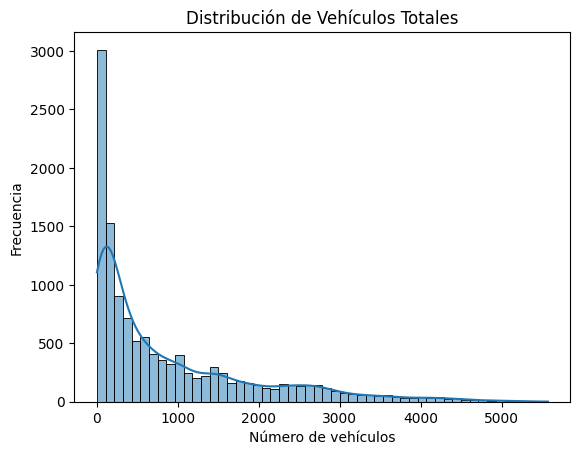

In [126]:
# Histograma de vehículos totales
sns.histplot(dataset_final["Vehículos totales"], kde=True)
plt.title("Distribución de Vehículos Totales")
plt.xlabel("Número de vehículos")
plt.ylabel("Frecuencia")

plt.show()

Observamos que es una distribución asimétrica donde hay muchas observaciones con poco tráfico a la derecha de la grafica lo cual representa pocos casos con tráfico muy alto.

### <u>Histograma de velocidad</u>

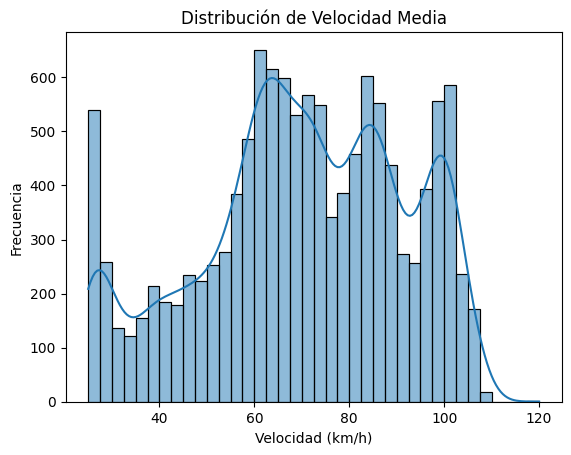

In [127]:
# Histograma de velocidad
sns.histplot(dataset_final["velocidad_media"], kde=True)
plt.title("Distribución de Velocidad Media")
plt.xlabel("Velocidad (km/h)")
plt.ylabel("Frecuencia")

plt.show()

En esta grafica observamos que los datos de las velocidades estan algo mas repartidos.

### <u>Matriz de correlacion</u>

Se calcula la matriz de correlación para identificar relaciones lineales entre las variables numéricas.

Este análisis permite detectar variables que aportan información similar y posibles problemas de redundancia.

Una correlación elevada no implica necesariamente que debamos eliminar una variable, pero nos ayuda a identificar aquellas que podrían estar aportando información repetida.

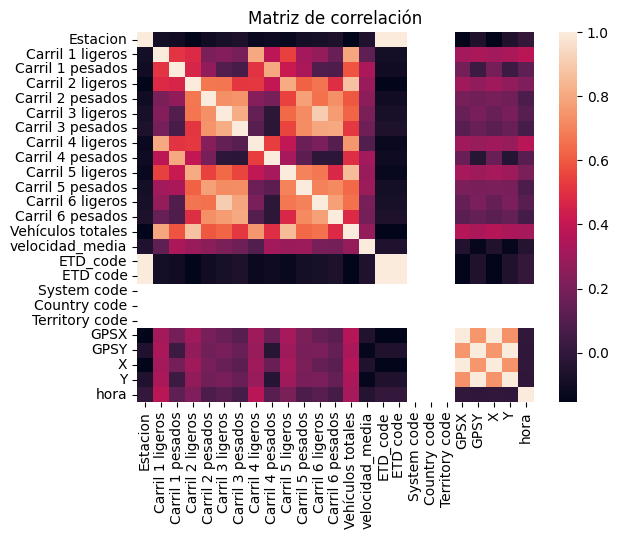

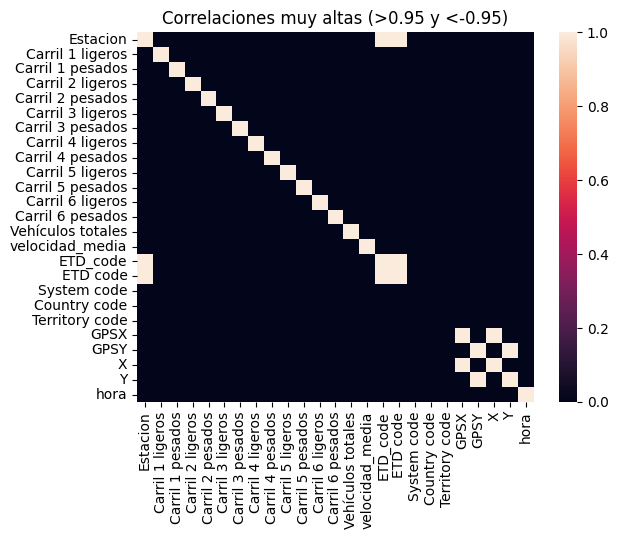

In [128]:
# Seleccionar solo columnas numéricas
df_num = dataset_final.select_dtypes(include=["int64", "float64"])

# Calcular correlaciones
corr = df_num.corr()

# Dibujar heatmap
sns.heatmap(corr, annot=False)
plt.title("Matriz de correlación")
plt.show()

# Para ver correlaciones fuertes
sns.heatmap(corr.abs() > 0.95, annot=False)
plt.title("Correlaciones muy altas (>0.95 y <-0.95)")
plt.show()

Observamos que hay una fuerte correlacion entre "GPSX" y "X"; "GPSY" y "Y"; ETD_code, ETD code y Estacion

### <u>Tráfico y velocidad por hora</u>

In [129]:
# Agrupar por cada hora del dia
trafico_hora = dataset_final.groupby("hora").agg({
    "Vehículos totales": "mean",
    "velocidad_media": "mean"
}).reset_index()

trafico_hora.head()

,hora,Vehículos totales,velocidad_media
0,0,365.641618,70.166059
1,1,218.575000,70.530089
2,2,120.864971,71.416809
3,3,86.680639,71.678308
4,4,82.979381,72.668942


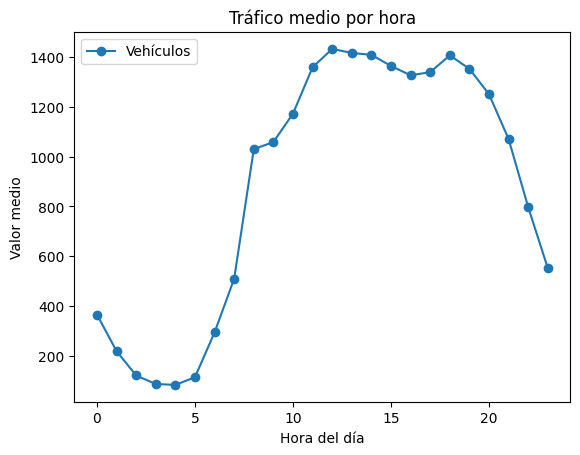

In [130]:
plt.plot(trafico_hora["hora"], trafico_hora["Vehículos totales"], marker="o", label="Vehículos")

plt.xlabel("Hora del día")
plt.ylabel("Valor medio")
plt.title("Tráfico medio por hora")
plt.legend()

plt.show()

Obervamos poco tráfico en madrugada y va creciendo progresivamente hacia horas diurnas y empieza a disminuir cuando empieza a anochecer

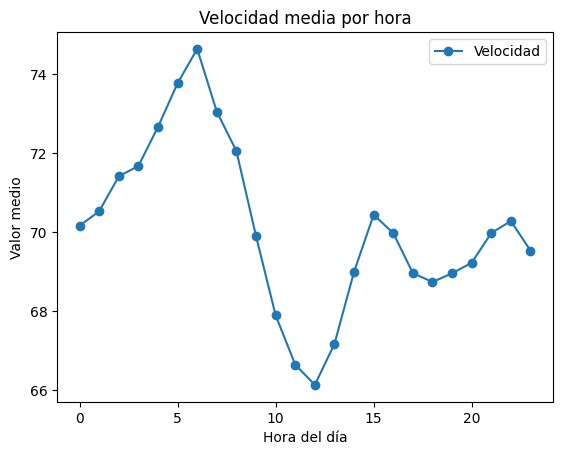

In [131]:
plt.plot(trafico_hora["hora"], trafico_hora["velocidad_media"], marker="o", label="Velocidad")

plt.xlabel("Hora del día")
plt.ylabel("Valor medio")
plt.title("Velocidad media por hora")
plt.legend()

plt.show()

Vemos que cuando empieza a haber más tráfico se empiza a disminuir la velocidad y viceversa

### <u>Análisis por estación</u>

Vamos ha hacer un analisis del trafico por estación

In [132]:
trafico_estacion = dataset_final.groupby("Estacion").agg({
    "Vehículos totales": "mean",
    "velocidad_media": "mean"
}).reset_index()

trafico_estacion.head()

,Estacion,Vehículos totales,velocidad_media
0,1,741.392857,63.222087
1,3,1471.803571,83.278835
2,11,393.892857,57.944070
3,12,1751.184524,99.334206
4,16,1378.285714,73.201041


In [133]:
# Ordenamos valores para que en ambas graficas las estaciones salgan en el mismo orden
trafico_estacion_sorted = trafico_estacion.sort_values(by="Vehículos totales", ascending=False)

#### **Tráfico por estación**

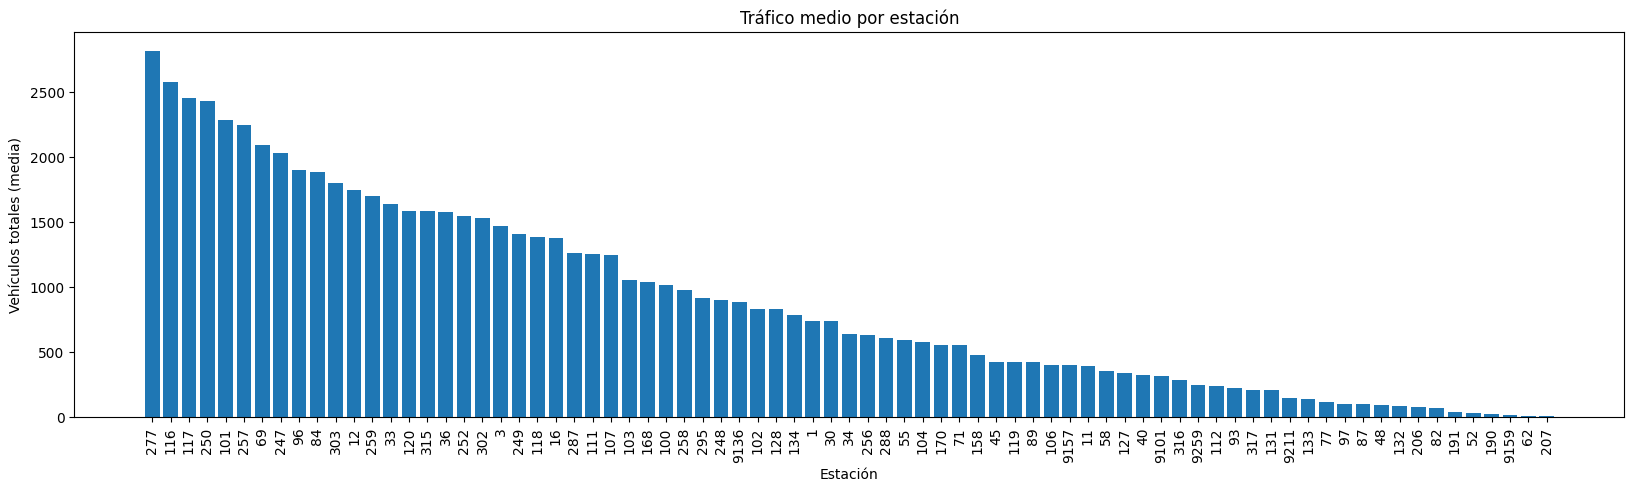

In [134]:
plt.figure(figsize=(20, 5))

plt.bar(trafico_estacion_sorted["Estacion"].astype(str), 
        trafico_estacion_sorted["Vehículos totales"])

plt.title("Tráfico medio por estación")
plt.xlabel("Estación")
plt.ylabel("Vehículos totales (media)")

plt.xticks(rotation=90)  # clave
plt.show()

#### **Velocidad por estación**

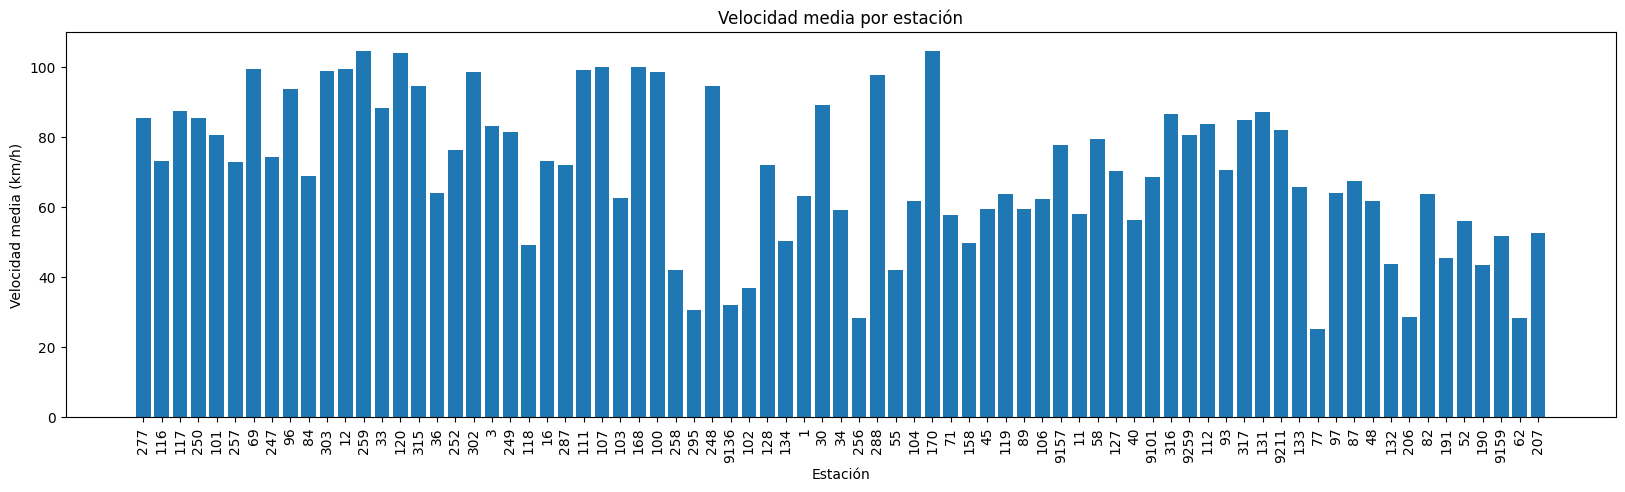

In [135]:
plt.figure(figsize=(20, 5))

plt.bar(trafico_estacion_sorted["Estacion"].astype(str), 
        trafico_estacion_sorted["velocidad_media"])

plt.title("Velocidad media por estación")
plt.xlabel("Estación")
plt.ylabel("Velocidad media (km/h)")

plt.xticks(rotation=90)
plt.show()

Podemos ver que las estaciones con alto tráfico no siempre tienen menor velocidad, si no que se vera diferencias claras entre zonas ya sean urbanas o interurbanas

# Preprocesamiento

In [136]:
df_clustering = dataset_final[[
    "Vehículos totales",
    "velocidad_media",
    "hora"
]]

### **Normalizacion**

Antes de aplicar los algoritmos de clustering, normalizamos las variables para evitar que aquellas con valores numéricos más elevados tengan una influencia desproporcionada en el cálculo de distancias.

Utilizamos StandardScaler, que transforma cada variable para que tenga una media de 0 y una desviación estándar de 1.

De esta forma, las variables de volumen de vehículos, velocidad y hora pueden contribuir de forma más equilibrada al proceso de agrupamiento.

K-Means, DBSCAN y el clustering jerárquico utilizan distancias para determinar agrupaciones.

In [137]:
from sklearn.preprocessing import StandardScaler

# Crear scaler
scaler = StandardScaler()

# Ajustar y transformar datos
df_scaled = scaler.fit_transform(df_clustering) # Calcula la media y la desviacion y posteriormente transforma los datos

# Convertimos a DataFrame
df_scaled = pd.DataFrame(df_scaled, columns=df_clustering.columns)

df_scaled.head()

,Vehículos totales,velocidad_media,hora
0,-0.747826,-0.131011,-1.527749
1,-0.796522,-0.165494,-1.383103
2,-0.812754,-0.157328,-1.238457
3,-0.803206,-0.185368,-1.093812
4,-0.783154,-0.015131,-0.949166


# Elección de algoritmo

Antes de nada importamos PCA que reduce las tres variables originales a dos componentes principales, permitiendo representar gráficamente los clusters.

Esta transformación se utiliza únicamente para visualizar los resultados, no para entrenar el modelo K-Means.

In [138]:
from sklearn.decomposition import PCA

## K-Means

Aqui aplicamos el algoritmo K-Means para agrupar los datos en distintos perfiles de tráfico.

El objetivo es identificar patrones como:

- Tráfico bajo vs alto

- Velocidad alta vs baja

- Diferencias según ubicación y trafico

Para empezar necesitamos determinar el número óptimo de clusters (k), para lo cual se utilizan dos técnicas:
- Método del codo (Elbow Method)

- Silhouette Score

### <u>Metodo del codo (Elbow Method)</u>

Analiza cómo disminuye la inercia al aumentar el número de clusters.

Apunte: La inercia mide la compactación interna de los clusters (cuanto menor, mejor).

In [139]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

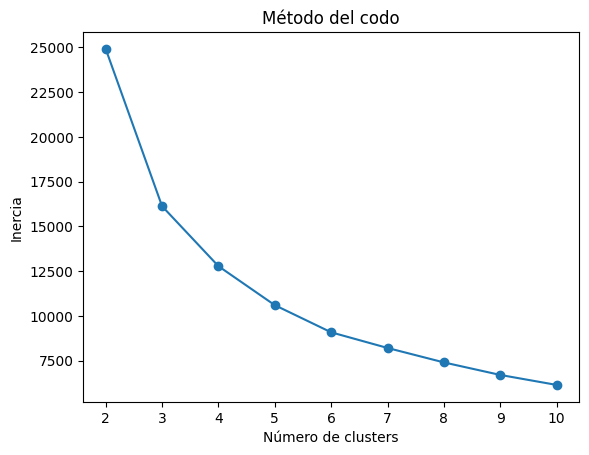

In [140]:
# Lista para almacenar la inercia de cada modelo
inertia = []

# Probamos distintos valores de k (número de clusters)
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled) # Aprende la estructura de los clusters
    inertia.append(kmeans.inertia_) # Guardamos la inercia

# Representamos de forma grafica las inercias
plt.plot(range(2, 11), inertia, marker='o')
plt.title("Método del codo")
plt.xlabel("Número de clusters")
plt.ylabel("Inercia")
plt.show()

### <u>Silhouette Score</u>

Evalúa la calidad de los clusters midiendo:
- Qué tan bien separados están

- Qué tan compactos son

Cuanto mas cerca del 1 los clusters estan bien definidos

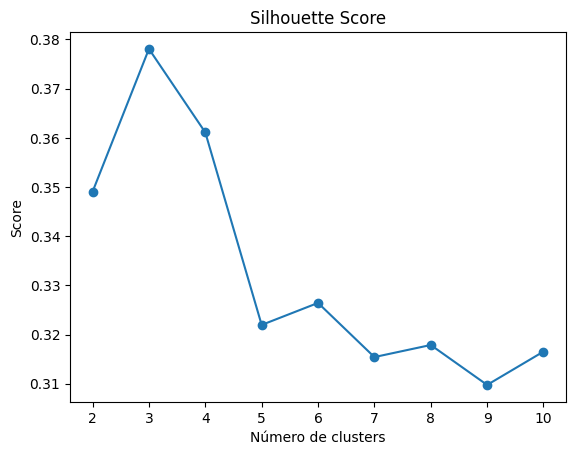

In [141]:
from sklearn.metrics import silhouette_score

# Aqui guardamos las puntuaciones de silhouette
silhouette_scores = []

# Probamos distintos valores de k (número de clusters)
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    # Aprende la estructura de los clusters y asigna cada punto al cluster mas cercano
    labels = kmeans.fit_predict(df_scaled) 
    
    score = silhouette_score(df_scaled, labels)
    silhouette_scores.append(score)

# Representamos de forma grafica las puntuaciones de silhouette
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title("Silhouette Score")
plt.xlabel("Número de clusters")
plt.ylabel("Score")
plt.show()

Vemos en ambas graficas el mejor K es de 3

### **Representacion de clusters con k-means**

Una vez determinado el número óptimo de clusters, se entrena el modelo final.

In [142]:
# Aplicamos K-Means con el número óptimo de clusters obtenido previamente (k=3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Aprende la estructura de los clusters y asigna cada punto al cluster mas cercano y asignamos cluster a cada observación
df_clustering["kmeans_cluster"] = kmeans.fit_predict(df_scaled) 

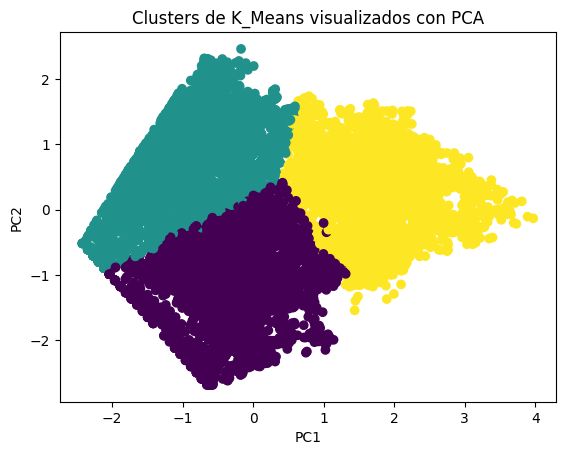

In [143]:
# Reducimos dimensionalidad a 2 dimensiones con PCA para visualizar los clusters
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

# Representación gráfica de los clusters de K-Means
plt.scatter(df_pca[:, 0], df_pca[:, 1], c=df_clustering["kmeans_cluster"])
plt.title("Clusters de K_Means visualizados con PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [144]:
print("Varianza explicada:", pca.explained_variance_ratio_)
print("Varianza acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada: [0.46849481 0.34784605]
Varianza acumulada: 0.8163408697635484


Observamos que es una muy buena varianza

### **Visualizacion grafica de las estaciones**

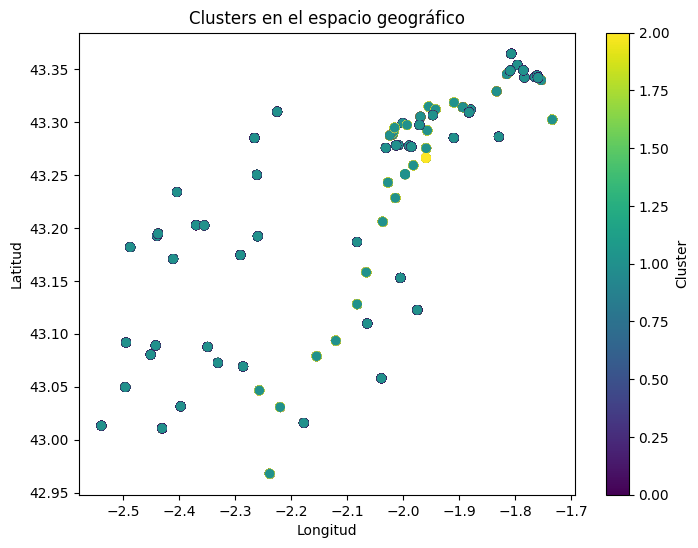

In [145]:
# Visualización geográfica
plt.figure(figsize=(8,6))
plt.scatter(
    dataset_final["X"],
    dataset_final["Y"],
    c=df_clustering["kmeans_cluster"]
)

plt.title("Clusters en el espacio geográfico")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.colorbar(label="Cluster")
plt.show()

Analizamos las características de cada cluster

In [146]:
df_clustering["kmeans_cluster"].value_counts()

kmeans_cluster
1    4823
0    4516
2    3086
Name: count, dtype: int64

Bastante equilibrado, el modelo ha sido capaz de identificar varios patrones distintos de tráfico (osea 3) sin concentrar todos los datos en un único grupo.

### **Análisis de cada cluster**

In [147]:
kmeans_stats = df_clustering.groupby("kmeans_cluster").agg(["mean", "median", "std"])
kmeans_stats

Vehículos totales                      velocidad_media  \
                            mean  median          std            mean   
kmeans_cluster                                                          
0                     573.409655   420.0   533.467836       54.074166   
1                     257.445573   146.0   305.726917       73.307036   
2                    2326.597537  2277.0  1009.121740       88.534231   

                                           hora                   
                   median        std       mean median       std  
kmeans_cluster                                                    
0               56.945526  17.666530  16.417848   17.0  4.415580  
1               73.235294  18.022604   4.486834    4.0  3.175201  
2               91.060160  12.908447  15.513610   16.0  4.450882

Cluster 0 (4.516 observaciones):
- Tráfico relativamente alto

- Velocidad reducida → indica cierta congestión

- Coincide con horas de tarde (posible hora punta)

Tráfico de tarde, densidad media-alta y circulación lenta

Cluster 1 (4.823 observaciones):
- Pocos vehículos

- Alta velocidad → circulación sin restricciones

- Horario claramente nocturno/madrugada

Tráfico noche/madrugada, condiciones óptimas

Cluster 2 (3.086 observaciones):
- Muchísimo tráfico

- Pero velocidad alta → no hay congestión

Tráfico intenso pero eficiente

In [148]:
df_clustering = df_clustering.drop(columns=["kmeans_cluster"])

## DBSCAN 

DBSCAN no necesita establecer previamente el número de clusters. Este algoritmo identifica agrupaciones a partir de la densidad de los datos, utilizando dos parámetros:

- eps: distancia máxima para considerar que dos puntos pertenecen a un mismo entorno.

- min_samples: número mínimo de puntos necesarios para considerar que una región tiene suficiente densidad.

In [149]:
from sklearn.cluster import DBSCAN

In [150]:
# Aplicamos DBSCAN con los dos parametros
dbscan = DBSCAN(eps=0.5, min_samples=10)

# Aprende la estructura de los clusters y asigna cada punto al cluster mas cercano y asignamos cluster a cada observación
df_clustering["dbscan_cluster"] = dbscan.fit_predict(df_scaled)

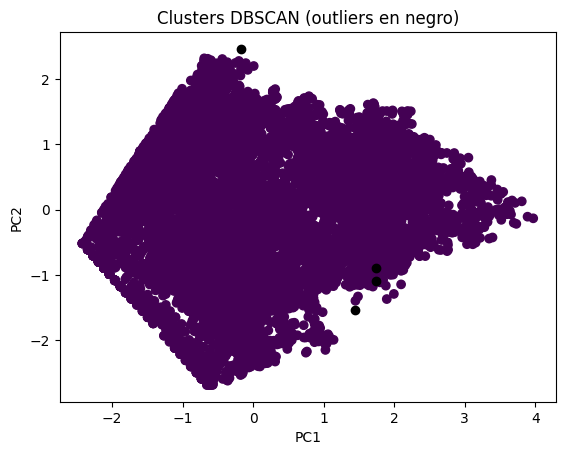

In [151]:
dbscan_labels = df_clustering["dbscan_cluster"]

# Identifica observaciones que no pertenecen a ningún grupo (ruido).
outliers_i = (dbscan_labels == -1)

# Representación gráfica de los clusters de DBSCAN
plt.scatter(df_pca[~outliers_i, 0], df_pca[~outliers_i, 1], c=dbscan_labels[~outliers_i])
plt.scatter(df_pca[outliers_i, 0], df_pca[outliers_i, 1], color="black") # De negro el ruido

plt.title("Clusters DBSCAN (outliers en negro)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

Analizamos las características de cada cluster

In [152]:
df_clustering["dbscan_cluster"].value_counts()

dbscan_cluster
 0    12421
-1        4
Name: count, dtype: int64

In [153]:
dbscan_stats = df_clustering.groupby("dbscan_cluster").agg(["mean", "median", "std"])
dbscan_stats

Vehículos totales                      velocidad_media  \
                            mean  median          std            mean   
dbscan_cluster                                                          
-1                   2768.500000  3392.5  1939.606575       62.853482   
 0                    885.595685   436.0  1046.537204       70.100957   

                                           hora                   
                   median        std       mean median       std  
dbscan_cluster                                                    
-1              46.352056  38.274717  12.000000   12.5  6.164414  
 0              70.830000  21.503438  11.561871   12.0  6.914172

Cluster 0 (12.421 observaciones): 

- Agrupa prácticamente todos los registros.

- Representan el comportamiento general del tráfico.

Ruido (-1) (4 observaciones): 

- Contiene los registros que el algoritmo no ha podido asignar al cluster principal.

- Observaciones aisladas o de baja densidad.
Podemos observar que DBSCAN agrupa prácticamente todas las observaciones en un único cluster y detecta únicamente cuatro registros como ruido.

Esto indica que, con los parámetros utilizados, el algoritmo no consigue identificar grupos diferenciados en los datos, ya que considera que la mayoría de las observaciones presentan características similares.

In [154]:
df_clustering = df_clustering.drop(columns=["dbscan_cluster"])

## Clustering jerárquico

Este método comienza considerando cada observación como un cluster independiente y va agrupando progresivamente aquellos grupos que presentan menor distancia entre sí.

El dendrograma permite visualizar cómo se van formando las agrupaciones y ayuda a seleccionar una distancia de corte para determinar el número final de clusters.

In [155]:
from scipy import cluster

Utilizamos el método complete, que calcula la distancia entre dos grupos considerando la mayor distancia entre sus observaciones.

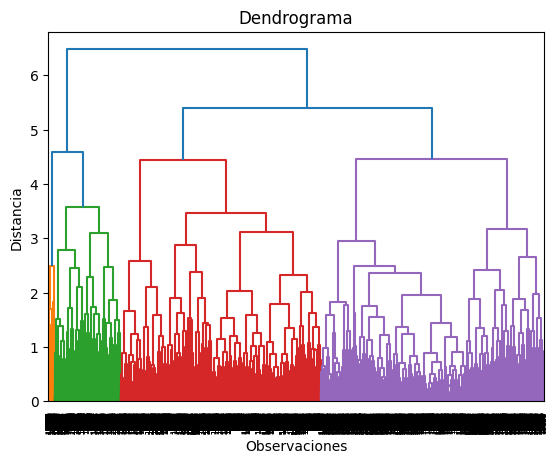

In [156]:
clusters = cluster.hierarchy.linkage(df_scaled, method='complete')

cluster.hierarchy.dendrogram(clusters)
plt.title("Dendrograma")
plt.xlabel("Observaciones")
plt.ylabel("Distancia")
plt.show()

Cortamos por el 5 ya que no nos genera una cantidad excesiva de clusters, en este caso 3

In [157]:
cut = 5
df_clustering["hac_cluster"] = cluster.hierarchy.fcluster(clusters, cut, criterion='distance')

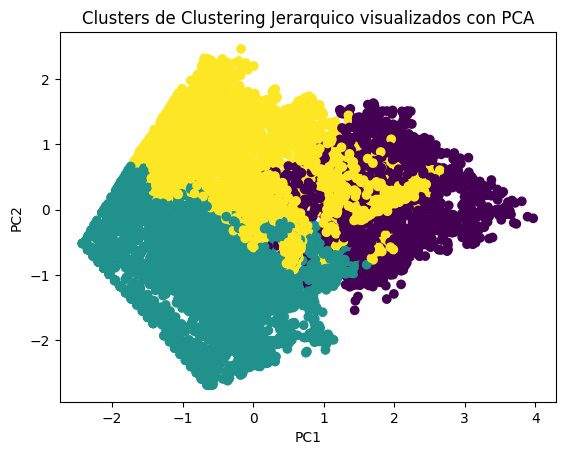

In [158]:
# Representación gráfica de los clusters de Clustering Jerarquico
plt.scatter(df_pca[:, 0], df_pca[:, 1], c=df_clustering["hac_cluster"])
plt.title("Clusters de Clustering Jerarquico visualizados con PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [159]:
df_clustering["hac_cluster"].value_counts()

hac_cluster
3    5584
2    5024
1    1817
Name: count, dtype: int64

In [160]:
hac_stats = df_clustering.groupby("hac_cluster").agg(["mean", "median", "std"])
hac_stats

Vehículos totales                     velocidad_media             \
                         mean  median         std            mean     median   
hac_cluster                                                                    
1                 2905.076500  2771.0  841.277015       80.176688  79.635404   
2                  493.047174   271.5  527.936142       50.193392  53.002100   
3                  582.998746   318.0  634.455118       84.728288  85.229062   

                             hora                   
                   std       mean median       std  
hac_cluster                                         
1            13.170061  14.081453   14.0  3.928599  
2            14.872676  13.760947   15.0  6.497705  
3            13.053124   8.763789    6.0  7.008266

Cluster 1 (1.817 observaciones): 

- Mayor volumen medio de vehículos (2.905)

- Velocidad media de 80,18

- Se concentra principalmente alrededor de las 14:00

- Situaciones de tráfico con un volumen elevado.

Cluster 2 (5.024 observaciones): 

- Menor volumen medio de vehículos (493)

- Velocidad media de 50,19

- Se concentra principalmente alrededor de las 15:00

- Situaciones de menor volumen y velocidad.

Cluster 3 (5.584 observaciones): 

- Volumen medio de vehículos de 583

- Mayor velocidad media (84,73). 

- Se concentra principalmente alrededor de las 09:00, 

- Situaciones de tráfico con menor volumen y mayor velocidad.

Observamos que el clustering jerárquico identifica tres grupos con características diferenciadas, principalmente en cuanto al volumen de vehículos, la velocidad media y la hora del día.

Esto indica que el algoritmo consigue separar distintos patrones de comportamiento del tráfico, distinguiendo situaciones con diferentes niveles de volumen y velocidad.

In [161]:
df_clustering = df_clustering.drop(columns=["hac_cluster"])

## HDBSCAN

HDBSCAN amplía el funcionamiento de DBSCAN mediante un análisis jerárquico de las densidades. Puede identificar clusters con diferentes densidades, sin necesidad de establecer un único radio de distancia (eps).

Al igual que DBSCAN, también permite identificar observaciones consideradas ruido.

Antes de empezar hay que instalarlo se hace con "pip install hdbscan"

In [162]:
import hdbscan

In [163]:
# Modelo
hdb = hdbscan.HDBSCAN(min_cluster_size=50)

# Aprende la estructura de los clusters y asigna cada punto al cluster mas cercano y asignamos cluster a cada observación
df_clustering["hdbscan_cluster"] = hdb.fit_predict(df_scaled)

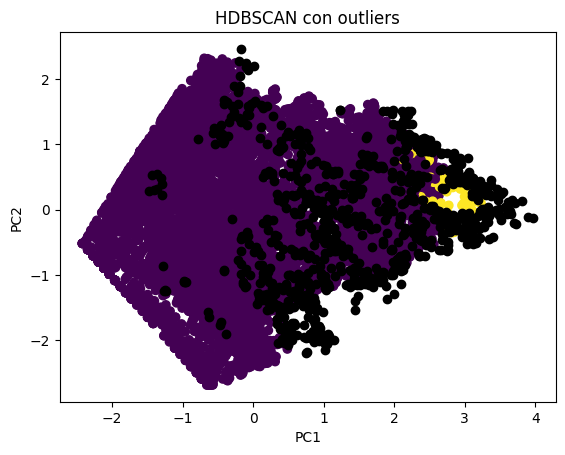

In [164]:
labels = df_clustering["hdbscan_cluster"]

outliers = (labels == -1)

plt.scatter(df_pca[~outliers, 0], df_pca[~outliers, 1], c=labels[~outliers])
plt.scatter(df_pca[outliers, 0], df_pca[outliers, 1], color="black")

plt.title("HDBSCAN con outliers")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [165]:
df_clustering["hdbscan_cluster"].value_counts()

hdbscan_cluster
 0    11410
-1      903
 1      112
Name: count, dtype: int64

In [166]:
hdbscan_stats = df_clustering.groupby("hdbscan_cluster").agg(["mean", "median", "std"])
hdbscan_stats

Vehículos totales                      velocidad_media  \
                             mean  median          std            mean   
hdbscan_cluster                                                          
-1                    2759.424142  2739.0  1213.678978       70.531756   
 0                     706.774847   358.0   817.739473       69.935538   
 1                    4062.473214  4041.5   204.665183       83.220871   

                                            hora                   
                    median        std       mean median       std  
hdbscan_cluster                                                    
-1               73.553705  19.864333  13.724252   14.0  5.294470  
 0               70.306438  21.696115  11.373707   11.0  7.023785  
 1               84.366422   3.607889  13.312500   13.0  2.620196

Cluster 0 (11.410 observaciones): 
- Agrupa la gran mayoría de los registros 

- Representa el comportamiento general del tráfico.

Cluster 1 (112 observaciones): 
- Identifica un grupo pequeño de observaciones con características diferenciadas respecto al grupo principal.

Ruido (-1) (903 observaciones): 
- Contiene los registros que el algoritmo no ha podido asignar a ningún cluster

- Se consideran observaciones aisladas o de baja densidad.

Podemos observar que HDBSCAN identifica un grupo claramente dominante, un segundo grupo mucho más reducido y una cantidad considerable de observaciones consideradas ruido.

Esto indica que existen algunas estructuras diferenciadas en los datos, aunque la mayor parte de las observaciones presentan comportamientos similares.

En comparación con DBSCAN, HDBSCAN permite identificar un segundo grupo de observaciones, aunque sigue existiendo una gran concentración de datos en un único cluster.

In [167]:
df_clustering = df_clustering.drop(columns=["hdbscan_cluster"])

# Conclusion final

Se han probado cuatro enfoques principales:

**K-Means**
Se utilizó el método del codo (Elbow Method) y el Silhouette Score para determinar el número óptimo de clusters.

Resultado: k = 3 clusters.

Resultados obtenidos: El modelo identifica claramente tres patrones de tráfico bien diferenciados.

**DBSCAN**
Parámetros utilizados: eps=0.5, min_samples=10
Resultados:
- 1 único cluster dominante (12381 puntos)
- 44 puntos considerados outliers
No detecta estructura real en los datos
Agrupa casi todo en un único grupo

**HDBSCAN**
Parámetro: min_cluster_size=50
Resultados:
- 1 cluster dominante (11410 puntos)
- 1 cluster pequeño (112 puntos)
- 903 outliers
Alta cantidad de ruido
Poca diferenciación real

**Clustering Jerárquico**
Método: linkage = complete

Resultado: cut = 5 que son 3 clusters

##### El modelo que mejor se adapta a los datos es:
K-Means con k = 3 clusters

Ya que:
- Detecta tres patrones de tráfico reales
- Genera clusters equilibrados
- Es estable y reproducible
- Interpretación clara y útil

Este análisis demuestra que:
- El tráfico presenta patrones claramente diferenciados
- Los métodos basados en centroides (K-Means) funcionan mejor que los basados en densidad en este caso